# HA2 — пространство и движение: реализация и визуализация

**Роль 3 — Даниил Копытов.** Адаптация `Seminars/Class03/Class_03_Instructor_Working_Notebook.ipynb` под результаты ролей 1–2.

Входной снимок: [ветка ha2-role2](https://github.com/noriginalno/embodied-ai-coolest-group/tree/ha2-role2/HomeAssignment/HA2), commit `5ca95838c2b38ae84cf26a23cdb1cf9be71ac4b6`.

Цель: построить полный типизированный граф и отдельную таксономию, проверить структуру, вычислить две оценки специфичности, сохранить исходные/нормализованные значения и изображения. **Концепты и рёбра не пересматриваются. Итоговая интерпретация и perturbation experiment относятся к роли 4 и здесь не выполняются.**

## 0. Что изменено относительно преподавательского ноутбука

- `concepts.csv` / `semantic_edges.csv` заменены на переданные `nodes.csv` / `edges.csv`; демонстрационные cup/car и интернет-запросы удалены.
- Полный граф — `MultiDiGraph`: разные типы связей между одной парой не перезаписывают друг друга. Таксономия — `DiGraph` со **всеми** узлами, включая изолированные.
- Нет единственного `ROOT='concept'`: используются все корни наблюдаемого DAG. Компоненты не объединяются вымышленными гиперонимами.
- Глубина вычисляется по кратчайшему и самому длинному пути от любого наблюдаемого корня. Диапазоны сохраняются и для потомков узлов с несколькими родителями.
- Расчётные функции вынесены в соседний `ha2_analysis.py`, чтобы роль 4 использовала ту же реализацию.

Запуск: Python 3.13, зависимости в `requirements.txt`; **Run All** из корня репозитория, `HomeAssignment/HA2` или `Seminars/Class03`. Во время выполнения сеть не используется.

In [1]:
from pathlib import Path
import sys
import importlib.metadata
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import display

# Only explicit paths; no recursive search or machine-specific absolute path.
bases = [Path.cwd(), *list(Path.cwd().parents)[:3]]
candidates = [p for base in bases for p in (base, base / 'HomeAssignment/HA2')]
DATA_DIR = next((p.resolve() for p in candidates if all(
    (p / f).is_file() for f in ('nodes.csv', 'edges.csv', 'ha2_analysis.py')
)), None)
if DATA_DIR is None:
    raise FileNotFoundError('Run from repository root, HomeAssignment/HA2 or Seminars/Class03.')
sys.path.insert(0, str(DATA_DIR))
from ha2_analysis import (
    load_inputs, build_graphs, audit_directions, compute_specificity,
    validate_scores, export_results, draw_taxonomy, draw_non_taxonomic, save_figures,
)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'svg.hashsalt': 'ha2-role3'})
print('Data:', DATA_DIR.relative_to(DATA_DIR.parents[1]))
print('Python:', sys.version.split()[0])
print({p: importlib.metadata.version(p) for p in ('networkx', 'pandas', 'numpy', 'matplotlib')})

Data: HomeAssignment/HA2
Python: 3.13.6
{'networkx': '3.7', 'pandas': '3.1.1', 'numpy': '2.5.5', 'matplotlib': '3.11.2'}


## 1. Переданные данные и дополнительная метаинформация

`nodes.csv` / `edges.csv` читаются без изменений. Определения целевых узлов копируются из `raw/Concepts_hw2.csv`, без генерации; отсутствие определения у вспомогательного узла сохраняется.

В исходном `nodes.csv` нет POS. Для синсетов с суффиксом `-N` POS извлекается из идентификатора. Остальная **лексическая**, а не онтологическая, POS-разметка хранится отдельно в `pos_annotations.csv` с provenance=`manual`; она не объявляется результатом RuWordNet. Для «внутри» принят ADV как POS названия отношения; возможное предложное употребление отмечено в sidecar. Это не создаёт ему таксономического родителя. Новые неразмеченные ID получат UNKNOWN, а не выдуманный POS.

**Размер входа:** 56 узлов, из них 25 целевых и 31 вспомогательный. Лимит 15–25 не считается автоматически соблюдённым за счёт исключения служебных категорий. Роль 3 сохраняет переданный инвентарь и лишь фиксирует это ограничение.

In [2]:
nodes, edges = load_inputs(DATA_DIR)
print(f'Узлов: {len(nodes)}; целевых: {nodes.is_target.eq("TRUE").sum()}; рёбер: {len(edges)}')
display(nodes[['node_id', 'label', 'node_type', 'POS', 'POS_provenance', 'definition']].head(12))
display(edges.groupby(['relation', 'provenance']).size().rename('count').to_frame())
display(nodes.groupby(['POS', 'POS_provenance']).size().rename('count').to_frame())

Узлов: 56; целевых: 25; рёбер: 53


,node_id,label,node_type,POS,POS_provenance,definition
0,C01,точка,target,NOUN,wordnet:source_id_suffix,"Определённое положение в пространстве, рассмат..."
1,C02,поверхность,target,NOUN,wordnet:source_id_suffix,"Внешняя граница тела, отделяющая его от окружа..."
2,C03,граница,target,NOUN,wordnet:source_id_suffix,"Предел, отделяющий одну пространственную облас..."
3,C04,расстояние,target,NOUN,wordnet:source_id_suffix,"Пространственная величина, характеризующая уда..."
4,C05,высота,target,NOUN,wordnet:source_id_suffix,Вертикальное расстояние от точки или объекта д...
5,C06,направление,target,NOUN,wordnet:source_id_suffix,Ориентация в пространстве относительно выбранн...
6,C07,путь,target,NOUN,wordnet:source_id_suffix,"Маршрут, по которому перемещаются между исходн..."
7,C08,вместилище,target,NOUN,wordnet:source_id_suffix,"Ограниченный участок пространства, предназначе..."
8,C09,отверстие,target,NOUN,wordnet:source_id_suffix,"Пустое пространство в теле или материале, чере..."
9,C10,между,target,ADP,manual:pos_annotations.csv,"Положение объекта в промежутке, ограниченном д..."


,,count
relation,provenance,
has_endpoint,manual,1
is_a,wordnet,50
passes_through,manual,1
specifies_location_of,manual,1


count
POS  POS_provenance                   
ADP  manual:pos_annotations.csv      2
ADV  manual:pos_annotations.csv      1
NOUN manual:pos_annotations.csv     34
     wordnet:source_id_suffix       19

## 2. Построение и проверка направлений

**Конвенция хранения:** `source=parent → target=child` для `is_a`. Это читается как **target is_a source**, а не наоборот. У нетаксономических предикатов направление читается буквально: координата → точка, путь → место, диаметр → центр.

Направления сверяются механически с колонками `parent/child` в `raw/Edges.csv` (с уже принятыми ролью 2 alias) и `parent_id/child_id` в сохранённой HA1-выгрузке. Это проверка переноса направления, **не повторная семантическая экспертиза гиперонимов**.

Проверяется DAG только для `is_a`: цикл в полном типизированном графе допустим. Никакие нетаксономические связи не становятся родителями.

In [3]:
G, T = build_graphs(nodes, edges)
direction_audit = audit_directions(DATA_DIR, nodes, edges)
assert direction_audit.source_direction_confirmed.all(), 'Unconfirmed source orientation'
assert set(G) == set(T) == set(nodes.node_id)
assert nx.is_directed_acyclic_graph(T)
print(f'Полный граф: {len(G)} узлов / {G.number_of_edges()} рёбер')
print(f'is_a: {len(T)} узлов / {T.number_of_edges()} рёбер; DAG=True')
print('Компонент is_a:', nx.number_weakly_connected_components(T))
print('Корней снимка:', sum(T.in_degree(n) == 0 for n in T))
print('Изолированные узлы снимка:', sorted(nx.isolates(T)))
print('Направлений подтверждено по исходным колонкам:', int(direction_audit.source_direction_confirmed.sum()))
display(direction_audit.head())

Полный граф: 56 узлов / 53 рёбер
is_a: 56 узлов / 50 рёбер; DAG=True
Компонент is_a: 16
Корней снимка: 28
Изолированные узлы снимка: ['A08', 'A18', 'A25', 'A27', 'C10', 'C11', 'C12', 'C21']
Направлений подтверждено по исходным колонкам: 50


,source,relation,target,direction,source_direction_confirmed,evidence
0,C18,is_a,C01,parent_to_child,True,HA1_submission/data/ruwordnet_edges.csv: paren...
1,C18,is_a,C02,parent_to_child,True,HA1_submission/data/ruwordnet_edges.csv: paren...
2,A02,is_a,C03,parent_to_child,True,HA1_submission/data/ruwordnet_edges.csv: paren...
3,A03,is_a,C04,parent_to_child,True,HA1_submission/data/ruwordnet_edges.csv: paren...
4,C04,is_a,C05,parent_to_child,True,HA1_submission/data/ruwordnet_edges.csv: paren...


## 3. Формулы: расхождения в источниках и принятые правила

Источники: `Class_03_Semantic_Networks_Lecture_and_Seminar_Expanded_Lecture.pptx`, слайды **9–10, 28**; исходный notebook, раздел 4 / ячейки 14–15 (нумерация с нуля).

Обозначения для выбранного `is_a`-DAG: $d_{min}(v)$ / $d_{max}(v)$ — минимальная / максимальная длина пути от **любого наблюдаемого корня**; корень имеет глубину 0. $n(v)$ — число **различных достижимых потомков**, не число путей, рёбер или непосредственных детей. $D_s=\max_v d_{min}(v)$, $D_l=\max_v d_{max}(v)$, $B=\max_v n(v)$.

| Вариант | Формула / область | Как сохраняется |
|---|---|---|
| Лекция 9 + notebook | $S_{depth}=d_{min}/D_s$ | Основной `S_depth`, глобально по всему переданному DAG |
| Лекция 10 + верх слайда 28 + notebook | $S_{breadth}=1-\ln(1+n)/\ln(1+B)$ | Основной `S_breadth`, та же глобальная область |
| Несколько путей / родителей | $[d_{min},d_{max}]$ | Сырые границы и нормированный интервал $[d_{min}/D_l,d_{max}/D_l]$ |
| Нижние инструкции слайда 28: нормировать внутри POS | Те же две формулы на **индуцированном** графе каждого POS | Дополнительные `S_depth_pos`, `S_breadth_pos` |
| Нижняя формула слайда 28 | $A=d+\ln((1+n)/N_{POS})$ | Отдельные `slide28_raw_min/max`; $d$ интерпретировано как $d_{min/max}$, $n$ как потомки; значения POS-restricted |

Последняя формула **не эквивалентна** inverse-descendant: при фиксированных $d,N$ её значение растёт с числом потомков. Значения $d$ и $n$ в этой строке слайда не определены отдельно — выбранная трактовка явно является допущением реализации. Основные два S ею не подменяются. Для диагностического сравнения добавлена min–max-нормализация её варианта с кратчайшей глубиной **внутри POS**: $(A-A_{min})/(A_{max}-A_{min})$; это решение реализации, **не формула преподавателя**.

`S_depth_longest=d_max/D_l` — альтернативный depth-score. Нормированный интервал всегда использует один $D_l$, чтобы верхняя граница не превышала 1. Основной `S_depth` использует $D_s$; если $D_s\ne D_l$, он не обязан совпадать с нижней границей интервала. В текущем снимке оба максимума равны 5.

### Область нормализации и неопределённые значения

- **Основная область — все 56 узлов**, включая вспомогательные и изолированные. Максимумы общие для всех компонентов, а не пересчитываются внутри каждого компонента. Искусственный суперкорень не добавляется даже временно.
- POS-вариант использует индуцированный подграф: меж-POS-рёбра не участвуют; его корни, глубины и потомки пересчитываются. Сохраняются $N$, оба максимума глубины, $B$, $\ln(1+B)$ и min/max альтернативной формулы.
- По fallback со слайда 28 при **N < 10** сохраняются сырые значения, нормированные оценки не выдаются (`NaN`, пустая ячейка CSV). Это относится к маленькой области нормализации, **не** к каждому маленькому компоненту внутри глобальной области.
- Нулевой знаменатель также даёт `NaN`, а не произвольный 0. У ADP (2 узла) и ADV (1 узел) POS-нормализация неприменима.
- Изолированный узел остаётся в таблице с $d=0,n=0$: глобальные формулы механически дадут 0 и 1. Поле `taxonomy_isolate=True` предупреждает, что это **не содержательное свидетельство специфичности**. Наличие нуля потомков означает только отсутствие потомков **в этом снимке**, а не во всём RuWordNet.
- `ln` — натуральный логарифм; в основном breadth отношение не зависит от основания. Вычисления/CSV сохраняют точность float; округление применяется только при выводе таблиц. Смешанный `S_mean` не рассчитывается.

In [4]:
specificity, normalization_constants = compute_specificity(T)
validate_scores(T, specificity)
target_specificity = specificity.loc[specificity.is_target.eq('TRUE')].copy()
columns = ['node_id', 'label', 'parent_ids', 'depth_min', 'depth_max', 'descendants',
           'S_depth', 'S_breadth', 'S_depth_range_min', 'S_depth_range_max', 'taxonomy_isolate']
display(target_specificity[columns].round(4))
display(normalization_constants.round(6))

,node_id,label,parent_ids,depth_min,depth_max,descendants,S_depth,S_breadth,S_depth_range_min,S_depth_range_max,taxonomy_isolate
25,C01,точка,C18,2,3,1,0.4,0.75,0.4,0.6,False
26,C02,поверхность,C18,2,3,0,0.4,1.00,0.4,0.6,False
27,C03,граница,A02,4,4,0,0.8,1.00,0.8,0.8,False
28,C04,расстояние,A03,4,4,1,0.8,0.75,0.8,0.8,False
29,C05,высота,C04,5,5,0,1.0,1.00,1.0,1.0,False
30,C06,направление,C18,2,3,1,0.4,0.75,0.4,0.6,False
31,C07,путь,C06,3,4,0,0.6,1.00,0.6,0.8,False
32,C08,вместилище,C18,2,3,0,0.4,1.00,0.4,0.6,False
33,C09,отверстие,C18,2,3,0,0.4,1.00,0.4,0.6,False
34,C10,между,,0,0,0,0.0,1.00,0.0,0.0,True


,scope,node_count,edge_count,max_depth_shortest,max_depth_longest,max_descendants,breadth_log_denominator,slide28_raw_min,slide28_raw_max,min_normalization_nodes,normalization_status
0,global,56,50,5,5,15,2.772589,-4.025352,0.974648,10,ok
1,POS:ADP,2,0,0,0,0,0.000000,-0.693147,-0.693147,10,raw_only_small_graph
2,POS:ADV,1,0,0,0,0,0.000000,0.000000,0.000000,10,raw_only_small_graph
3,POS:NOUN,53,50,5,5,15,2.772589,-3.970292,1.029708,10,ok


### Несколько родителей и сравнение широких/узких узлов

Первой таблицей показаны все узлы, у которых несколько непосредственных родителей **или** расходятся глубины путей (например, вследствие нескольких родителей у предка). Непосредственные родители и достижимые корни перечислены отдельно.

Затем автоматически выбираются по три широких (не менее двух наблюдаемых потомков) и узких (целевые, без наблюдаемых потомков, но с родителем) примера. Это проверяемая табличная выборка по структуре, **не итоговая интерпретация**. Изоляты не используются как примеры узких категорий.

In [5]:
multiple_routes = specificity.loc[(specificity.parent_count > 1) | (specificity.depth_min != specificity.depth_max)]
display(multiple_routes[['node_id', 'label', 'parent_ids', 'root_ids', 'root_path_count',
                        'depth_min', 'depth_max', 'S_depth_range_min', 'S_depth_range_max']].round(4))
broad = specificity.loc[specificity.descendants >= 2].sort_values(
    ['descendants', 'node_id'], ascending=[False, True]).head(3).assign(sample='broad_in_snapshot')
narrow = target_specificity.loc[(target_specificity.descendants == 0) & (target_specificity.parent_count > 0)].sort_values(
    ['depth_min', 'node_id'], ascending=[False, True]).head(3).assign(sample='narrow_in_snapshot')
assert len(broad) == len(narrow) == 3
display(pd.concat([broad, narrow])[['sample', 'node_id', 'label', 'depth_min', 'depth_max',
                                  'descendants', 'S_depth', 'S_breadth']].round(4))
display(target_specificity[['node_id', 'label', 'POS', 'S_depth_pos', 'S_breadth_pos',
                            'slide28_raw_min', 'slide28_raw_max', 'slide28_minmax_pos']].round(4))

,node_id,label,parent_ids,root_ids,root_path_count,depth_min,depth_max,S_depth_range_min,S_depth_range_max
25,C01,точка,C18,A05;HA1:153782-N,2,2,3,0.4,0.6
26,C02,поверхность,C18,A05;HA1:153782-N,2,2,3,0.4,0.6
30,C06,направление,C18,A05;HA1:153782-N,2,2,3,0.4,0.6
31,C07,путь,C06,A05;HA1:153782-N,2,3,4,0.6,0.8
32,C08,вместилище,C18,A05;HA1:153782-N,2,2,3,0.4,0.6
33,C09,отверстие,C18,A05;HA1:153782-N,2,2,3,0.4,0.6
37,C13,ширина,A12;A13;A14;A15;A16,A12;A13;A14;A15;A16,5,1,1,0.2,0.2
38,C14,глубина,A12;A13;A14;A15;A16;A17,A12;A13;A14;A15;A16;A17,6,1,1,0.2,0.2
39,C15,центр,C01,A05;HA1:153782-N,2,3,4,0.6,0.8
40,C16,угол,A06;A07,A06;A07,2,1,1,0.2,0.2


,sample,node_id,label,depth_min,depth_max,descendants,S_depth,S_breadth
55,broad_in_snapshot,HA1:153782-N,ПОСТОЯННАЯ СУЩНОСТЬ,0,0,15,0.0,0.0000
2,broad_in_snapshot,A04,ФИЗИЧЕСКАЯ СУЩНОСТЬ,1,1,9,0.2,0.1695
3,broad_in_snapshot,A05,ФИЗИЧЕСКИ СУЩЕСТВУЮЩАЯ СУЩНОСТЬ,0,0,9,0.0,0.1695
29,narrow_in_snapshot,C05,высота,5,5,0,1.0,1.0000
27,narrow_in_snapshot,C03,граница,4,4,0,0.8,1.0000
31,narrow_in_snapshot,C07,путь,3,4,0,0.6,1.0000


,node_id,label,POS,S_depth_pos,S_breadth_pos,slide28_raw_min,slide28_raw_max,slide28_minmax_pos
25,C01,точка,NOUN,0.4,0.75,-1.2771,-0.2771,0.5386
26,C02,поверхность,NOUN,0.4,1.00,-1.9703,-0.9703,0.4000
27,C03,граница,NOUN,0.8,1.00,0.0297,0.0297,0.8000
28,C04,расстояние,NOUN,0.8,0.75,0.7229,0.7229,0.9386
29,C05,высота,NOUN,1.0,1.00,1.0297,1.0297,1.0000
30,C06,направление,NOUN,0.4,0.75,-1.2771,-0.2771,0.5386
31,C07,путь,NOUN,0.6,1.00,-0.9703,0.0297,0.6000
32,C08,вместилище,NOUN,0.4,1.00,-1.9703,-0.9703,0.4000
33,C09,отверстие,NOUN,0.4,1.00,-1.9703,-0.9703,0.4000
34,C10,между,ADP,NaN,NaN,-0.6931,-0.6931,NaN


## 4. Контроль разделения слоёв

Повторная сборка только по `is_a` должна дать **побитно одинаковые табличные значения** обеих оценок и всех их диагностик. Это проверка реализации, а не perturbation experiment роли 4: исходные данные не изменяются, новые семантические рёбра не предлагаются.

In [6]:
_, category_only = build_graphs(nodes, edges.loc[edges.relation.eq('is_a')])
category_scores, category_norms = compute_specificity(category_only)
pd.testing.assert_frame_equal(specificity, category_scores, check_exact=True)
pd.testing.assert_frame_equal(normalization_constants, category_norms, check_exact=True)
print('PASS: нетаксономические рёбра не меняют ни одну расчётную колонку.')

PASS: нетаксономические рёбра не меняют ни одну расчётную колонку.


## 5. Визуализация без смешения типов

Для читаемости сделаны два изображения: **полная таксономия со всеми узлами** и отдельные панели всех трёх нетаксономических связей. Типизированный граф целиком сохраняется также в JSON.

Таксономический layout иерархический, детерминированный, без Graphviz-зависимости. Вертикальный ранг основан на **максимальной** глубине: каждая стрелка идёт вниз, в том числе при множественном наследовании. Это ранг рисунка, не замена основного score на кратчайшей глубине. Цвет заливки различает целевые/вспомогательные узлы, рамка — наблюдаемые корни. Нетаксономические предикаты подписаны и имеют отдельные цвета/легенду.

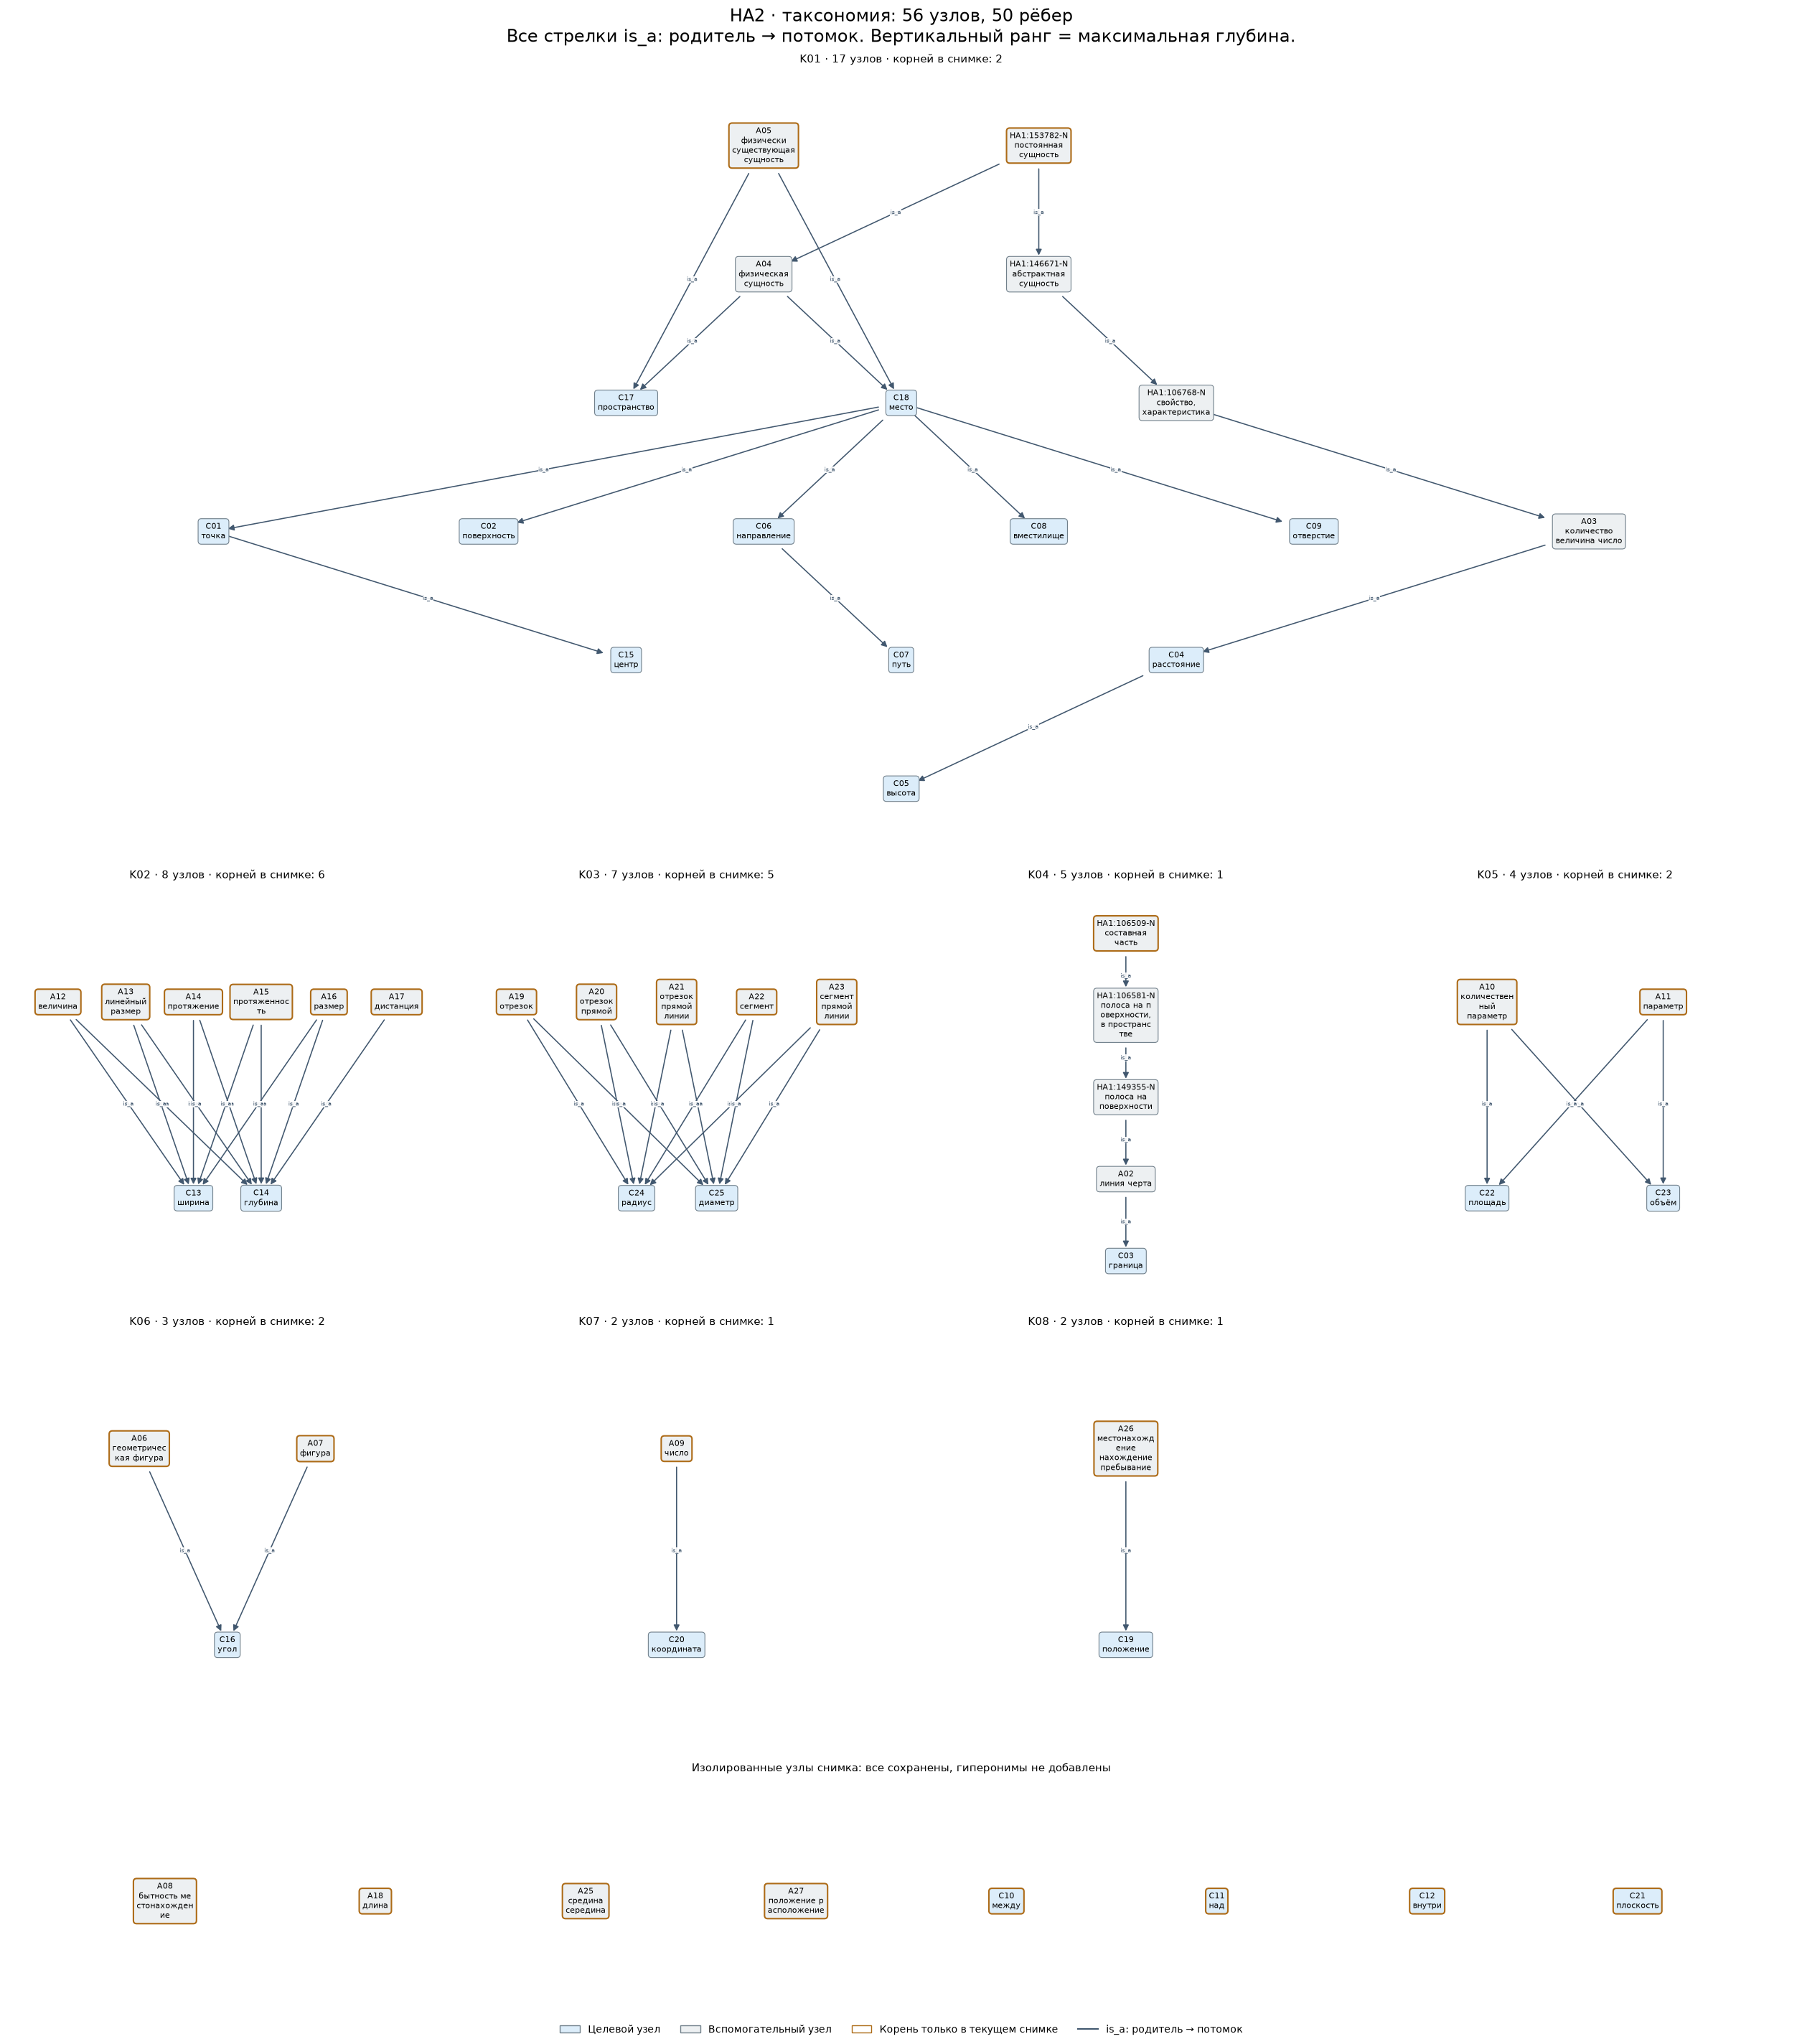

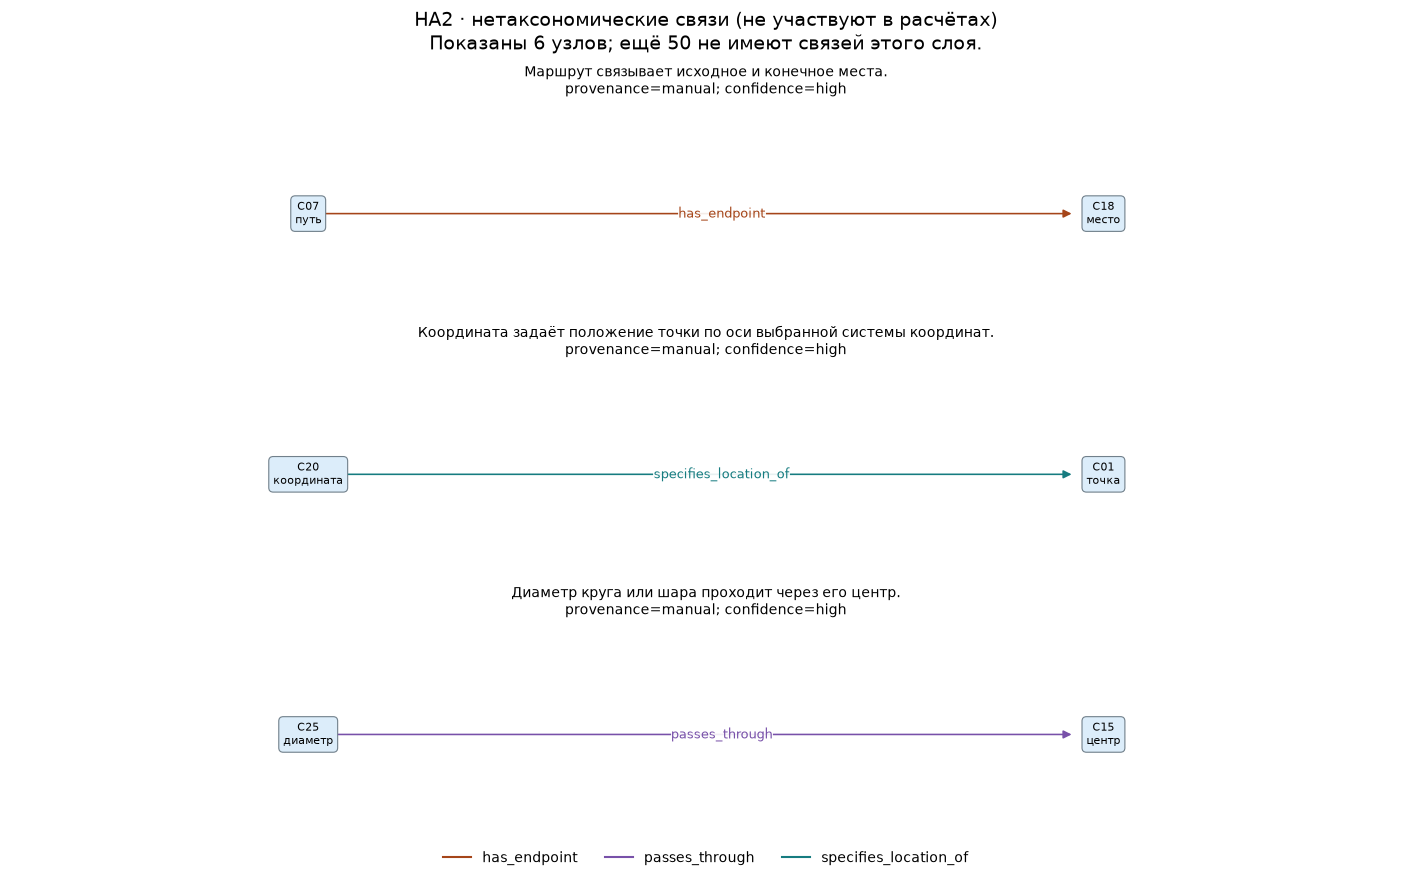

In [7]:
taxonomy_figure = draw_taxonomy(T)
relations_figure = draw_non_taxonomic(G)
save_figures(DATA_DIR, taxonomy_figure, relations_figure)
display(taxonomy_figure)
display(relations_figure)
plt.close(taxonomy_figure)
plt.close(relations_figure)

In [8]:
validation = export_results(DATA_DIR, nodes, edges, G, T, specificity,
                            normalization_constants, direction_audit)
assert validation['all_nodes_scored']
assert validation['non_taxonomic_edges_used_for_specificity'] == 0
print({k: validation[k] for k in ('node_count', 'typed_edge_count', 'taxonomy_is_DAG',
                                'taxonomy_weak_components', 'all_nodes_scored')})
print('Сохранены:')
for folder in ('results', 'figures'):
    for path in sorted((DATA_DIR / folder).iterdir()):
        print(path.relative_to(DATA_DIR))

{'node_count': 56, 'typed_edge_count': 53, 'taxonomy_is_DAG': True, 'taxonomy_weak_components': 16, 'all_nodes_scored': True}
Сохранены:
results/direction_audit.csv
results/node_attributes.csv
results/normalization.csv
results/run_manifest.json
results/specificity.csv
results/specificity_targets.csv
results/taxonomy_graph.json
results/typed_graph.json
results/validation.json
figures/non_taxonomic.png
figures/non_taxonomic.svg
figures/taxonomy.png
figures/taxonomy.svg


## 6. Артефакты и граница роли 3

- `results/specificity.csv` — все 56 узлов; `specificity_targets.csv` — срез из 25 целевых, **без пересчёта нормализации**.
- `results/normalization.csv` — глобальные и POS-константы; `direction_audit.csv` — сверка направления; `validation.json` — структурные проверки и предупреждения; `run_manifest.json` — SHA исходной ветки, версии библиотек и SHA-256 входов.
- `results/typed_graph.json` / `taxonomy_graph.json` — машинно-читаемые графы текущего снимка; `node_attributes.csv` — дополненные метаданные без изменения входного `nodes.csv`.
- `figures/taxonomy.{png,svg}` и `figures/non_taxonomic.{png,svg}` — изображения с легендами.

**Для роли 4:** сначала сохранить baseline отдельно, затем для каждого варианта вызывать те же `build_graphs` и `compute_specificity`, передавая полный список узлов. Хранить таблицу констант каждого варианта: изменение глобального максимума может сдвинуть нормированные значения и в другом компоненте. Нельзя смешивать основные глобальные S с POS- или slide28-диагностиками в сравнении «более 0.1». Если нужен контроль с фиксированными baseline-знаменателями, это отдельный явно помеченный режим анализа.

Perturbation, оценка устойчивости и итоговый текст интерпретации здесь намеренно отсутствуют.